# 2. Fix the OSM data once, for every output

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/02_osm_fixes.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/02_osm_fixes.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

OSM data has errors. In duckOSM you write a fix one time, in a fixes file. The build and every export read the file, so all outputs show the corrected data.

In this notebook you change the speed limit of one road (the OSM tag `maxspeed`), build again, and examine the route, the map and six outputs.

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
try:
    import duckosm
except ImportError:
    %pip install -q "duckosm[widget,sumo]" roadstyle
    import duckosm
print("duckosm", duckosm.__version__)

duckosm 0.8.0


## Build Monaco without a fix

In [2]:
area = duckosm.get("Monaco", out="data")      # the OSM file of Monaco and its boundary
net = duckosm.build(pbf=area.pbf, boundary=area.boundary, modes=["driving"],
                    output="data/monaco.duckdb")   # the driving network: a duckosm.Network
net

cut: 34794 nodes, 5693 ways, 343 relations

Output: data/monaco.duckdb

mode,edges,nodes,km
driving,"2,840","1,768",96.2


## Find a route

The fastest route by car from Fontvieille to Larvotto. The table shows the OSM ways that the route uses most.

In [3]:
a, b = (7.4155, 43.7285), (7.4335, 43.7468)    # Fontvieille and Larvotto, as (lon, lat)
before = net.route_points(a, b)                # the fastest route by car
print(f"{before['time_s']:.0f} s, {before['length_m']:.0f} m, {len(before['edges'])} edges")

229 s, 2939 m, 75 edges


In [4]:
from IPython.display import HTML    # to show a table with no index column

# the three OSM ways with the longest part of the route
ways = net.sql("""SELECT osm_id, any_value(name) AS name, any_value(maxspeed_kmh) AS maxspeed_kmh,
                         round(sum(length_m)) AS length_m
                  FROM driving.edges WHERE list_contains($ids, edge_id)
                  GROUP BY osm_id ORDER BY length_m DESC LIMIT 3""", {"ids": before["edges"]})
HTML(ways.to_html(index=False, na_rep=""))

osm_id,name,maxspeed_kmh,length_m
4230891,Boulevard Louis II,50.0,356.0
503633031,Avenue Princesse Grace,50.0,223.0
166399479,Boulevard Albert 1er,50.0,216.0


## Write the fix

Make the speed limit of the first way 10 km/h, for example for road works. `extra.tag_edits` sets OSM tags. The other keys of the file are in [The fixes file](https://khoshkhah.github.io/duckOSM/guides/edit-osm-data/#the-fixes-file). You can also make fixes on a map with `duckosm edit`.

In [5]:
way = int(ways.osm_id[0])    # the OSM id of the way to fix
fixes = f"""extra:
  tag_edits:
    - {{type: way, id: {way}, set: {{maxspeed: '10'}}}}
"""
open("osm_fixes.yaml", "w").write(fixes)    # the fixes file
print(fixes)

extra:
  tag_edits:
    - {type: way, id: 4230891, set: {maxspeed: '10'}}



## Build again with the fix

In [6]:
fixed = duckosm.build(pbf=area.pbf, boundary=area.boundary, modes=["driving"],
                      output="data/monaco_fixed.duckdb", fixes="osm_fixes.yaml")   # the same build, with the fixes file
after = fixed.route_points(a, b)    # the same route on the fixed network
print(f"before: {before['time_s']:.0f} s, {before['length_m']:.0f} m")
print(f"after:  {after['time_s']:.0f} s, {after['length_m']:.0f} m")

Output: data/monaco_fixed.duckdb

before: 229 s, 2939 m
after:  252 s, 3302 m


The new route goes around the slow road. Run the cell to see the live map: you can zoom, and click a road to see its columns. This page shows a picture of the map.

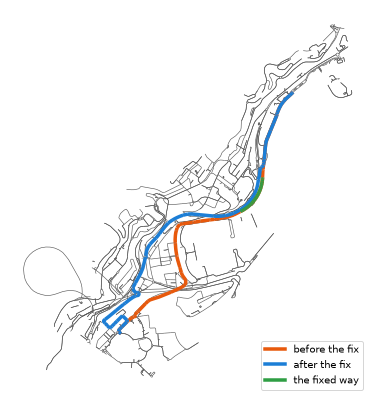

In [7]:
gdf = fixed.edges()                                 # the driving edges of the fixed network
way_edges = {"edges": gdf.edge_id[gdf.osm_id == way]}  # the edges of the fixed way, as a route to draw
# the two routes and the fixed way as lines on the map, each in its own color
fixed.map(route={"before the fix": before, "after the fix": after, "the fixed way": way_edges})

## The edge ids do not change

A tag fix does not change the shape of the network. So each edge keeps its `edge_id`, and data joined on the ids stays correct.

In [8]:
ids_before = set(net.edges().edge_id)    # the edge ids of the two builds
ids_after = set(fixed.edges().edge_id)
print(len(ids_before), "edges before,", len(ids_after), "after, the same ids:", ids_before == ids_after)

2840 edges before, 2840 after, the same ids: True


## Every output takes the fix

Each export reads the fixed database, and `quack` reads the fixes file. Each cell writes one output and reads the speed of one edge of the fixed way from it.

In [9]:
import duckdb

edge = int(gdf.edge_id[gdf.osm_id == way].iloc[0])    # one edge of the fixed way
speeds = {"database (km/h)": float(gdf.maxspeed_kmh[gdf.edge_id == edge].iloc[0])}    # the speed in each output

# a GeoPackage, read with DuckDB
fixed.to_gis("out/monaco.gpkg", modes=["driving"])
con = duckdb.connect()
con.load_extension("spatial")
speeds["GeoPackage (km/h)"] = con.execute(
    "SELECT maxspeed_kmh FROM st_read('out/monaco.gpkg', layer='edges_driving') WHERE edge_id = ?", [edge]).fetchone()[0]

GIS out/monaco.gpkg: done in 0.1 s

In [10]:
import gzip
import xml.etree.ElementTree as ET

# SUMO: the speed of the edge in the plain XML, in m/s
sumo = fixed.to_sumo("out/sumo", run_netconvert=False)
speeds["SUMO (km/h)"] = round(float(ET.parse(sumo["edg"]).find(f".//edge[@id='{edge}']").get("speed")) * 3.6, 1)

# MATSim: the free speed of the link, in m/s
fixed.to_matsim("out/matsim.xml.gz")
link = ET.parse(gzip.open("out/matsim.xml.gz")).find(f".//link[@id='{edge}']")
speeds["MATSim (km/h)"] = round(float(link.get("freespeed")) * 3.6, 1)

SUMO out/sumo: done in 0.1 s

MATSim out/matsim.xml.gz: done in 0.1 s

In [11]:
# GMNS: the free speed of the link (link_id is the edge_id)
fixed.to_gmns("out/gmns.duckdb")
speeds["GMNS (km/h)"] = duckdb.connect("out/gmns.duckdb", read_only=True).execute(
    "SELECT free_speed FROM gmns_driving.link WHERE link_id = ?", [edge]).fetchone()[0]

# the QuackOSM table: the OSM tag of the way, from the OSM file and the fixes file
quack = duckosm.quack(area.pbf, out="out", name="monaco", fixes="osm_fixes.yaml", formats=["geoparquet"])
speeds["QuackOSM table (tag)"] = con.execute(
    f"SELECT tags['maxspeed'] FROM '{quack[0]}' WHERE feature_id = 'way/{way}'").fetchone()[0]
speeds

GMNS out/gmns.duckdb: done in 9.4 s

out/monaco_quack.parquet

{'database (km/h)': 10.0,
 'GeoPackage (km/h)': 10.0,
 'SUMO (km/h)': 10.0,
 'MATSim (km/h)': 10.0,
 'GMNS (km/h)': 10.0,
 'QuackOSM table (tag)': '10'}